In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    RocCurveDisplay
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [20]:
import os

print(os.listdir("/content"))

['.config', 'Telco_Customer_Churn_Dataset  (1).csv', 'sample_data']


In [21]:
df = pd.read_csv('/content/Telco_Customer_Churn_Dataset  (1).csv')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [22]:
df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [23]:
print("Rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

Rows and columns: (7043, 21)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService  

In [24]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [25]:
# TotalCharges is stored as text in the original CSV.
# Convert it to numeric; blank or invalid entries become NaN.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Missing values after conversion:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Missing values after conversion:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Duplicate rows: 0


In [26]:
print(df["Churn"].value_counts())
print("\nChurn percentage:")
print((df["Churn"].value_counts(normalize=True) * 100).round(2))

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentage:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


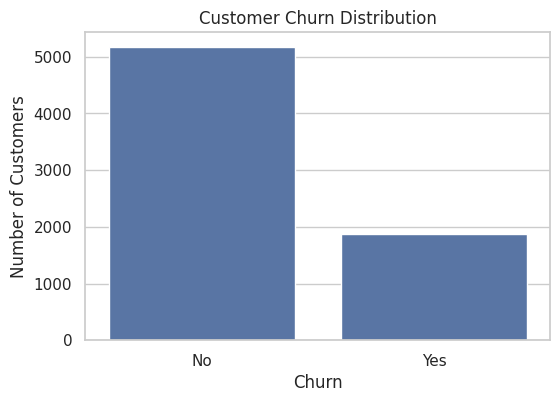

In [27]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

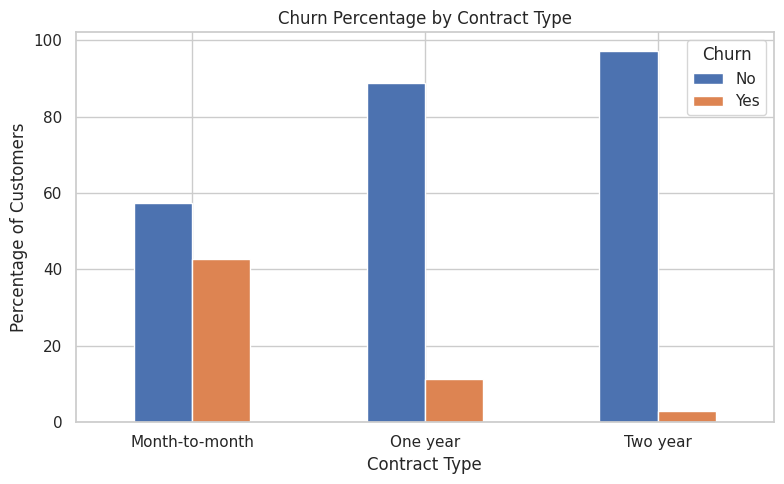

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


In [28]:
contract_churn = pd.crosstab(df["Contract"], df["Churn"], normalize="index") * 100
contract_churn.plot(kind="bar", figsize=(8, 5))
plt.title("Churn Percentage by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

contract_churn.round(2)

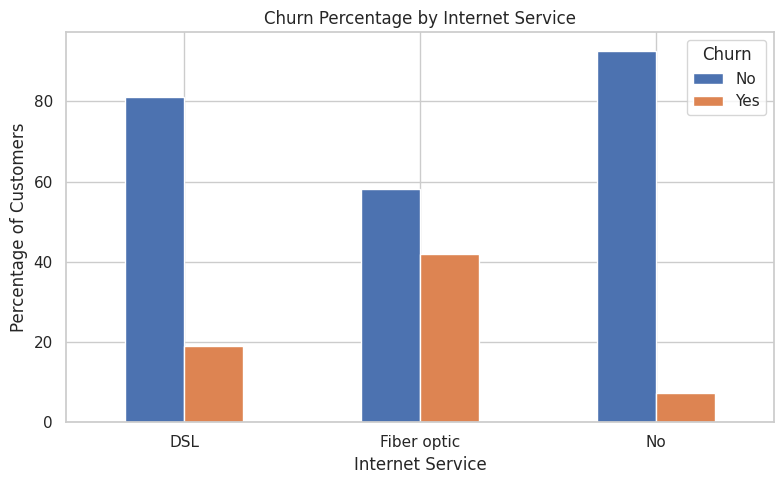

In [29]:
internet_churn = pd.crosstab(df["InternetService"], df["Churn"], normalize="index") * 100
internet_churn.plot(kind="bar", figsize=(8, 5))
plt.title("Churn Percentage by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

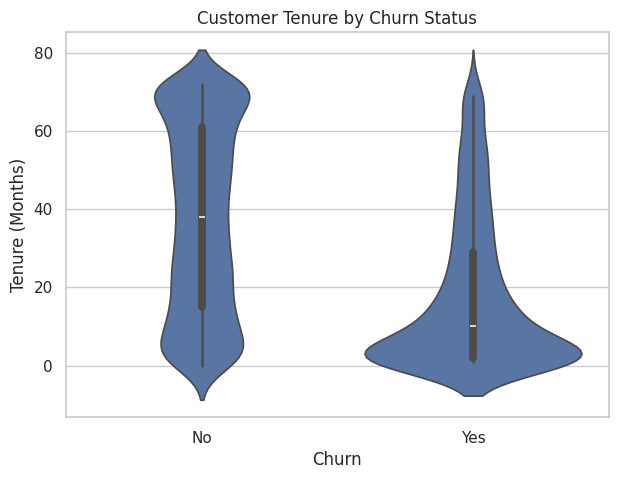

In [30]:
plt.figure(figsize=(7, 5))
sns.violinplot(data=df, x="Churn", y="tenure")
plt.title("Customer Tenure by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")
plt.show()

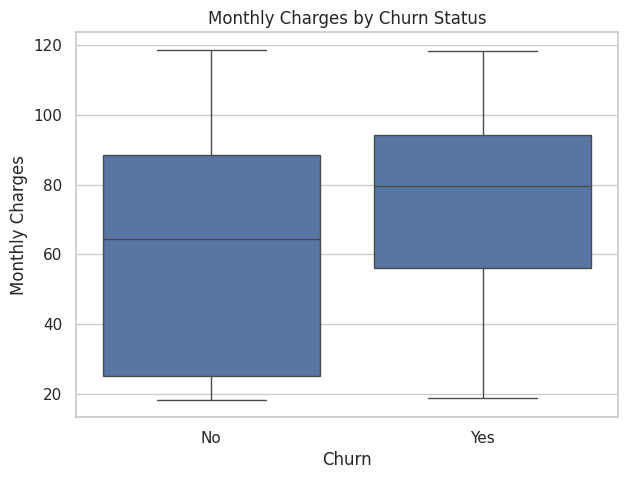

In [31]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.show()

In [32]:
# customerID is an identifier, not a useful behavioural predictor.
# The selected features are based on the project brief and business relevance.
selected_features = [
    "Contract",
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "InternetService",
    "OnlineSecurity",
    "TechSupport",
    "PaymentMethod",
    "PaperlessBilling",
    "SeniorCitizen"
]

X = df[selected_features].copy()
y = df["Churn"].map({"No": 0, "Yes": 1})

print("Selected features:")
print(selected_features)
print("\nTarget mapping: No = 0, Yes = 1")
print("Feature data shape:", X.shape)
print("Target data shape:", y.shape)

Selected features:
['Contract', 'tenure', 'MonthlyCharges', 'TotalCharges', 'InternetService', 'OnlineSecurity', 'TechSupport', 'PaymentMethod', 'PaperlessBilling', 'SeniorCitizen']

Target mapping: No = 0, Yes = 1
Feature data shape: (7043, 10)
Target data shape: (7043,)


In [33]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (5634, 10)
Testing features: (1409, 10)
Training target: (5634,)
Testing target: (1409,)


In [34]:
numeric_features = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["int64", "float64"]).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']
Categorical features: ['Contract', 'InternetService', 'OnlineSecurity', 'TechSupport', 'PaymentMethod', 'PaperlessBilling']


In [35]:
# Numerical data: fill missing values with the median, then scale.
numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical data: fill missing values with the most frequent value,
# then convert categories into numeric columns.
categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_preprocessor, numeric_features),
    ("cat", categorical_preprocessor, categorical_features)
])

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [36]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced"
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=6, min_samples_split=20,
        class_weight="balanced", random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, min_samples_leaf=3,
        class_weight="balanced", random_state=42, n_jobs=-1
    )
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
model_scores = {}

for name, model in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])
    scores = cross_val_score(
        pipeline, X_train, y_train,
        cv=cv, scoring="f1", n_jobs=-1
    )
    model_scores[name] = scores.mean()
    print(f"{name}: Mean cross-validation F1-score = {scores.mean():.4f}")

Logistic Regression: Mean cross-validation F1-score = 0.6211
Decision Tree: Mean cross-validation F1-score = 0.6086
Random Forest: Mean cross-validation F1-score = 0.6235


,Model,Mean CV F1-score
2,Random Forest,0.623513
0,Logistic Regression,0.621149
1,Decision Tree,0.608593


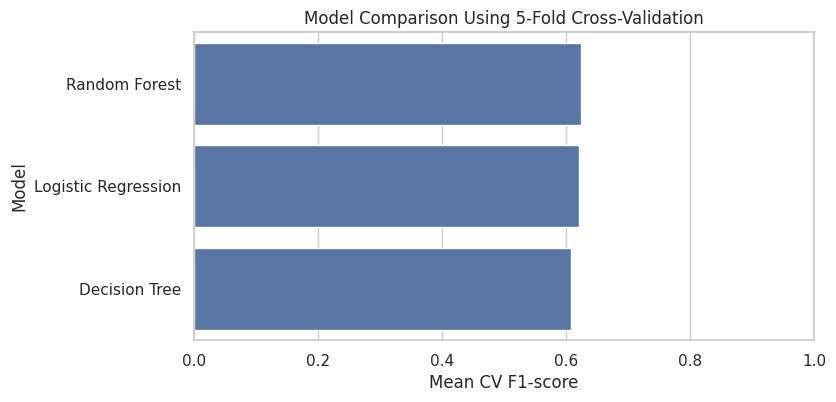

Selected model: Random Forest


In [37]:
score_table = pd.DataFrame({
    "Model": list(model_scores.keys()),
    "Mean CV F1-score": list(model_scores.values())
}).sort_values("Mean CV F1-score", ascending=False)

display(score_table)

plt.figure(figsize=(8, 4))
sns.barplot(data=score_table, x="Mean CV F1-score", y="Model")
plt.title("Model Comparison Using 5-Fold Cross-Validation")
plt.xlim(0, 1)
plt.show()

best_model_name = score_table.iloc[0]["Model"]
best_model = models[best_model_name]

print("Selected model:", best_model_name)

In [38]:
final_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", best_model)
])

final_model.fit(X_train, y_train)
print("Model training completed successfully.")

Model training completed successfully.


In [39]:
y_pred = final_model.predict(X_test)
y_probability = final_model.predict_proba(X_test)[:, 1]

print("Predictions generated successfully.")
print("First 10 predictions:", y_pred[:10])

Predictions generated successfully.
First 10 predictions: [0 1 0 1 0 1 1 0 0 1]


In [40]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_probability)

print(f"Accuracy:  {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall:    {recall * 100:.2f}%")
print(f"F1-score:  {f1 * 100:.2f}%")
print(f"ROC-AUC:   {roc_auc:.4f}")

Accuracy:  77.29%
Precision: 55.84%
Recall:    68.98%
F1-score:  61.72%
ROC-AUC:   0.8330


In [41]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Churn", "Churn"],
    zero_division=0
))

              precision    recall  f1-score   support

    No Churn       0.88      0.80      0.84      1035
       Churn       0.56      0.69      0.62       374

    accuracy                           0.77      1409
   macro avg       0.72      0.75      0.73      1409
weighted avg       0.79      0.77      0.78      1409



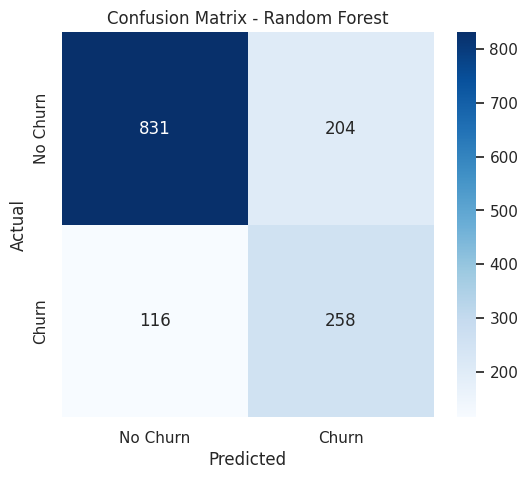

In [42]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)
plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

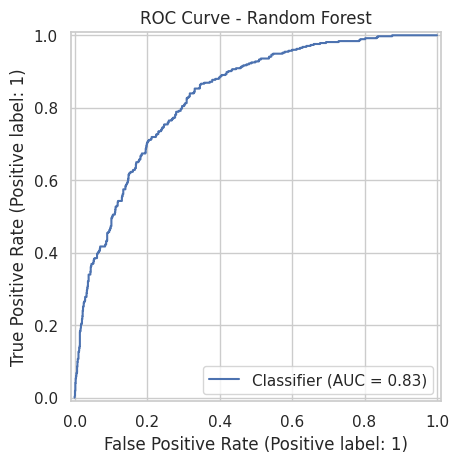

In [43]:
RocCurveDisplay.from_predictions(y_test, y_probability)
plt.title(f"ROC Curve - {best_model_name}")
plt.show()

,Feature,Importance
2,num__TotalCharges,0.170739
0,num__tenure,0.162379
1,num__MonthlyCharges,0.145967
4,cat__Contract_Month-to-month,0.121584
10,cat__OnlineSecurity_No,0.058657
13,cat__TechSupport_No,0.053577
6,cat__Contract_Two year,0.048940
8,cat__InternetService_Fiber optic,0.040014
18,cat__PaymentMethod_Electronic check,0.034107
5,cat__Contract_One year,0.021120


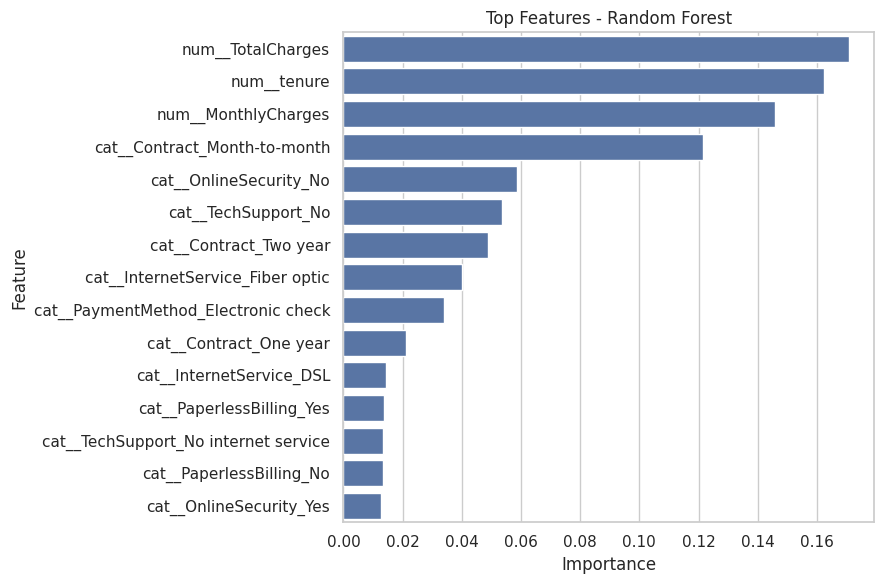

In [44]:
# Get the names created by preprocessing.
feature_names = final_model.named_steps["preprocessor"].get_feature_names_out()
classifier = final_model.named_steps["classifier"]

if hasattr(classifier, "feature_importances_"):
    importance_values = classifier.feature_importances_
    importance_label = "Feature Importance"
elif hasattr(classifier, "coef_"):
    importance_values = np.abs(classifier.coef_[0])
    importance_label = "Absolute Logistic Regression Coefficient"
else:
    importance_values = None

if importance_values is not None:
    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importance_values
    }).sort_values("Importance", ascending=False).head(15)

    display(importance_df)

    plt.figure(figsize=(9, 6))
    sns.barplot(data=importance_df, x="Importance", y="Feature")
    plt.title(f"Top Features - {best_model_name}")
    plt.tight_layout()
    plt.show()
else:
    print("Feature importance is not available for this model.")

In [45]:
print("Churn rate by contract type (%):")
print((pd.crosstab(df["Contract"], df["Churn"], normalize="index")["Yes"] * 100).round(2))

print("\nAverage tenure by churn status:")
print(df.groupby("Churn")["tenure"].mean().round(2))

print("\nAverage monthly charges by churn status:")
print(df.groupby("Churn")["MonthlyCharges"].mean().round(2))

Churn rate by contract type (%):
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Yes, dtype: float64

Average tenure by churn status:
Churn
No     37.57
Yes    17.98
Name: tenure, dtype: float64

Average monthly charges by churn status:
Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64


In [46]:
import joblib

joblib.dump(final_model, "customer_churn_model.pkl")
print("Trained model saved as customer_churn_model.pkl")

Trained model saved as customer_churn_model.pkl
